In [8]:
# !pip install -q -U langchain-nebius langchain langgraph rich python-dotenv tavily-python

In [1]:
from common import LLM_MODEL, API_BASE, API_KEY

API_BASE:https://api-ad-ops-prod-advibe.nioint.com
model:claude-deepseek-v4-pro（ADVibe）


In [ ]:
from dotenv import load_dotenv
from langchain.agents import AgentState
from langchain_anthropic import ChatAnthropic
from langchain_community.tools import TavilySearchResults
from langgraph.graph import StateGraph
from rich.console import Console
from rich.console import Console
from rich.markdown import Markdown

console = Console()

load_dotenv(override=True)
console = Console()

# Initialize the tool. We can set the max number of results to keep the context concise.
search_tool = TavilySearchResults(max_results=2)
# It's crucial to give the tool a clear name and description for the agent
search_tool.name = "web_search"
search_tool.description = "A tool that can be used to search the internet for up-to-date information on any topic, including news, events, and current affairs."
tools = [search_tool]

llm = ChatAnthropic(
    model_name=LLM_MODEL,
    api_key=API_KEY,
    base_url=API_BASE,
    max_tokens=16000,
)

llm_with_tools = llm.bind_tools(tools=tools)

In [13]:

from langgraph.prebuilt import ToolNode


def react_agent_node(state: AgentState):
    """The agent node that thinks and decides the next step."""
    console.print("--- REACT AGENT: Thinking... ---")
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}


def router_function(state: AgentState) -> str:
    """Inspects the agent's last message to decide the next step."""
    last_message = state["messages"][-1]
    if last_message.tool_calls:
        # The agent has requested a tool call
        console.print(f"--- ROUTER: Decision is to call a tool. ---")
        return "call_tool"
    else:
        # The agent has provided a final answer
        console.print(f"--- ROUTER: Decision is to finish.---")
        return "__end__"

In [14]:


# The ReAct graph with its characteristic loop
react_graph_builder = StateGraph(AgentState)
react_graph_builder.add_node("agent", react_agent_node)
react_graph_builder.add_node("tools", ToolNode([search_tool])) # We reuse the tool_node from before

react_graph_builder.set_entry_point("agent")
react_graph_builder.add_conditional_edges(
    "agent",
    # We can reuse the same router function
    router_function,
    # The map now defines the routing logic
    {"call_tool": "tools", "__end__": "__end__"}
)

# This is the key difference: the edge goes from the tool node BACK to the agent
react_graph_builder.add_edge("tools", "agent")

react_agent_app = react_graph_builder.compile()

Tool-using agent graph compiled successfully!


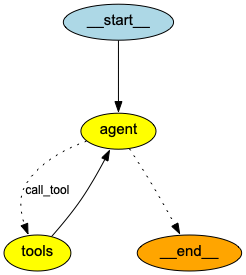

In [16]:
print("Tool-using agent graph compiled successfully!")

# Visualize the graph
try:
    from IPython.display import Image, display
    png_image = react_agent_app.get_graph().draw_png()
    display(Image(png_image))
except Exception as e:
    print(f"Graph visualization failed: {e}. Please ensure pygraphviz is installed.")

In [ ]:
from IPython.display import Markdown, display

multi_step_query = "Who is the current CEO of the company that created the sci-fi movie 'Dune', and what was the budget for that company's most recent film?"

console.print(f"[bold yellow]Testing ReAct agent on a multi-step query:[/bold yellow] '{multi_step_query}'\n")

final_react_output = None
# Stream the output to see the step-by-step reasoning
for chunk in react_agent_app.stream({"messages": [("user", multi_step_query)]}, stream_mode="values"):
    final_react_output = chunk
    console.print(f"--- [bold purple]Current State Update[/bold purple] ---")
    chunk['messages'][-1].pretty_print()
    console.print("\n")

console.print("\n--- [bold green]Final Output from ReAct Agent[/bold green] ---")
final_message = (
    final_react_output["messages"][-1]
    if final_react_output
    and isinstance(final_react_output, dict)
    and "messages" in final_react_output
    and final_react_output["messages"]
    else None
)

if final_message is not None:
    display(Markdown(final_message.content))
else:
    console.print("[bold red]No final output produced by the agent.[/bold red]")


Testing ReAct agent on a multi-step query: 'Who is the current CEO of the company that created the sci-fi movie 
'Dune', and what was the budget for that company's most recent film?'

--- Current State Update ---

================================ Human Message =================================

Who is the current CEO of the company that created the sci-fi movie 'Dune', and what was the budget for that company's most recent film?


--- REACT AGENT: Thinking... ---

--- ROUTER: Decision is to call a tool. ---

...

--- ROUTER: Decision is to finish.---

--- Current State Update ---

================================== Ai Message ==================================

[{'signature': None, 'thinking': 'Wikipedia key people says Joshua Grode CEO (2017–present). Good.\n\nNow final answer should be accurate. Need maybe mention "Legendary Entertainment produced Dune (2021)". CEO Joshua Grode. Most recent feature film: A Minecraft Movie, released April 4, 2025, budget $150 million. If counting Legendary\'s documentary Blue Scuti: Tetris Crasher, it premiered June 2025 but budget not publicly reported. We can include caveat.\n\nLet\'s craft final: "The Dune (2021) film was produced by Legendary Entertainment. Its current CEO is Joshua Grode. Legendary\'s most recent major theatrical film is A Minecraft Movie (April 2025), with a reported budget of $150 million. (If including documentaries, Legendary\'s unscripted doc Blue Scuti: Tetris Crasher premiered in June 2025, but no budget is publicly available.)"\n\nNeed ensure "created" perhaps if they mean director? Company that cr

--- Final Output from ReAct Agent ---

NameError: name 'Markdown' is not defined